<a href="https://colab.research.google.com/github/tbloesch/deepLearning/blob/main/final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final project

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tbloesch/deepLearning/blob/main/notebooks/final_project.ipynb)

The code lives in `src/dlproject/`. This notebook only imports and runs it.
Edit the code in VS Code, push to GitHub, then re-run the setup cell in Colab to pull the changes
(and *Runtime → Restart session* so the new code is loaded).

**Contents**
1. Setup
2. Data
3. Data sanity checks
4. Model
5. Training
6. Evaluation

## 1. Setup

In [ ]:
# Setup: works both in Colab and locally in VS Code
import os, sys
from pathlib import Path

REPO_URL = 'https://github.com/tbloesch/deepLearning.git'

if 'google.colab' in sys.modules:
    repo = Path('/content/deepLearning')
    if repo.exists():
        !git -C {repo} pull -q
    else:
        !git clone -q {REPO_URL} {repo}
    !pip install -q gdown torchinfo torchmetrics
else:
    repo = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.chdir(repo)                      # data/ is downloaded into the repo root
sys.path.insert(0, str(repo / 'src'))

# Auto-reload edited modules (Colab's IPython autoreload is broken on Python 3.12+, so skip it there;
# in Colab, after pulling new code use Runtime -> Restart session and re-run the cells)
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except ModuleNotFoundError:
    pass

In [ ]:
# Switches for slow steps
RUN_SLOW_CHECKS = False   # duplicate search (runs ResNet-18 over every image)
TRAIN_MODEL     = True    # False = load the saved checkpoint instead of training

In [ ]:
from dlproject.config import get_device
from dlproject.data import download_data, get_datasets, get_loader, describe_dataset, describe_batch
from dlproject import checks

device = get_device()
data_dir = download_data()

Using device: cuda


Downloading...
From (original): https://drive.google.com/uc?id=1MK1FxwqvPrFvrtDsCccjSQIHWimpMWgG
From (redirected): https://drive.google.com/uc?id=1MK1FxwqvPrFvrtDsCccjSQIHWimpMWgG&confirm=t&uuid=4d34047c-c43c-4823-b634-e3cf4cc490f4
To: /content/deepLearning/data.zip
100%|██████████| 98.2M/98.2M [00:01<00:00, 58.3MB/s]


Dataset ready.


## 2. Data

In [ ]:
train_dataset, val_dataset = get_datasets(data_dir)
train_loader = get_loader(train_dataset)

describe_dataset(train_dataset)
print()
describe_batch(train_loader)

Classes:          ['akhalTeke', 'appaloosa', 'arabian', 'friesian', 'orlovTrotter', 'percheron', 'vladimirHeavyDraft']
Class to index:   {'akhalTeke': 0, 'appaloosa': 1, 'arabian': 2, 'friesian': 3, 'orlovTrotter': 4, 'percheron': 5, 'vladimirHeavyDraft': 6}
Number of images: 1239

First item:
  Image shape: torch.Size([3, 224, 224])
  Label:       0 (akhalTeke)

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Labels in batch:   [5, 1, 1, 5, 4, 2, 3, 2, 0, 0, 0, 5, 3, 4, 6, 0, 3, 2, 3, 6, 2, 1, 0, 2, 3, 2, 3, 1, 2, 2, 6, 4]


## 3. Data sanity checks

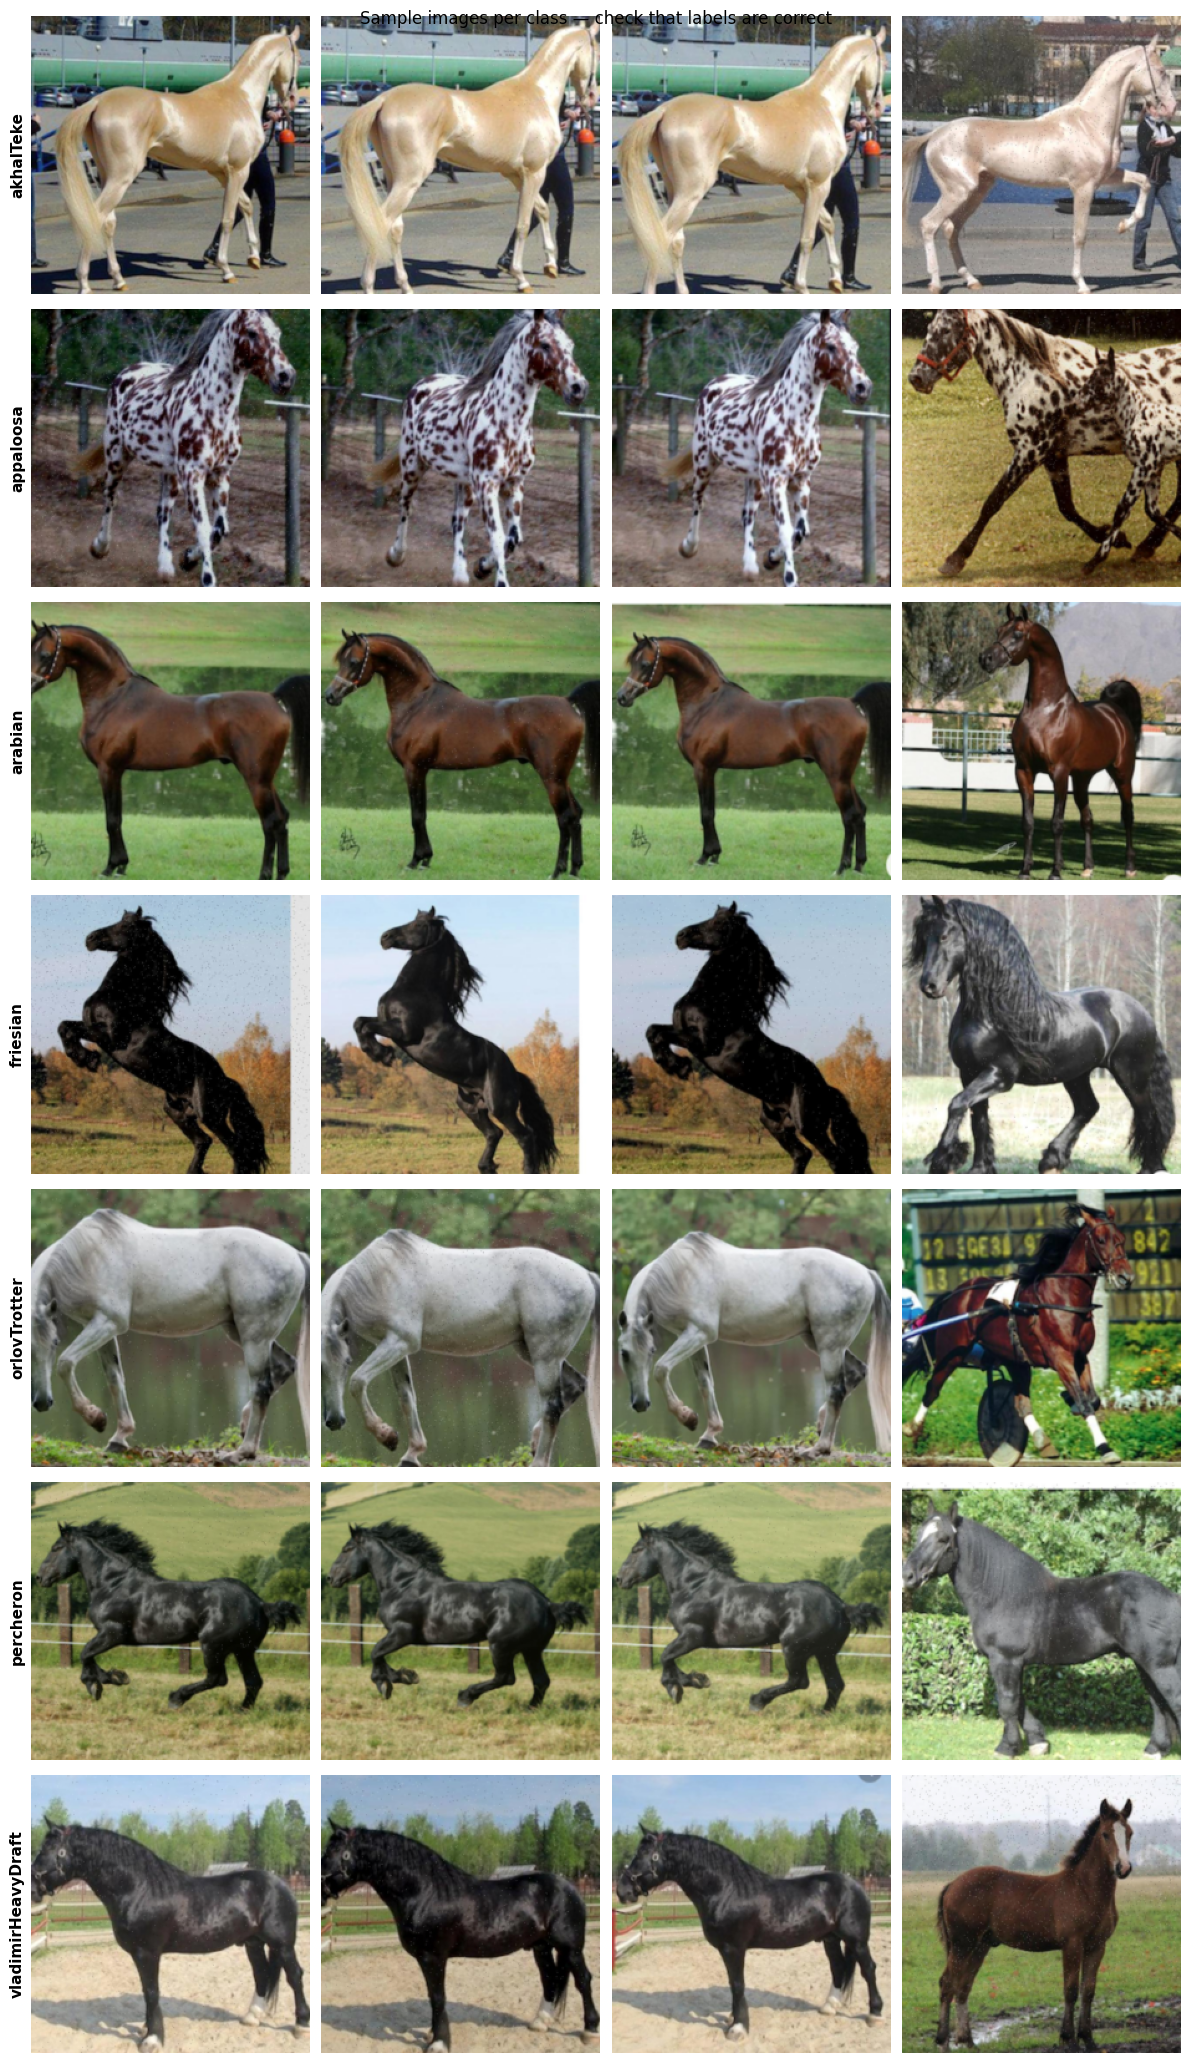

In [ ]:
checks.visualise_samples(train_dataset, train_dataset.classes)

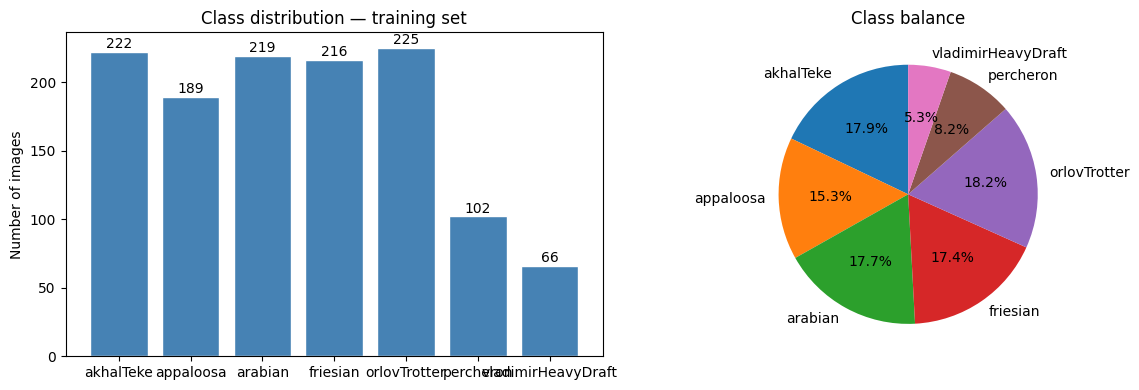

Total: 1239 images
Min class: 66 (vladimirHeavyDraft)
Max class: 225 (orlovTrotter)


In [ ]:
checks.check_class_distribution(train_dataset, train_dataset.classes, 'training set')

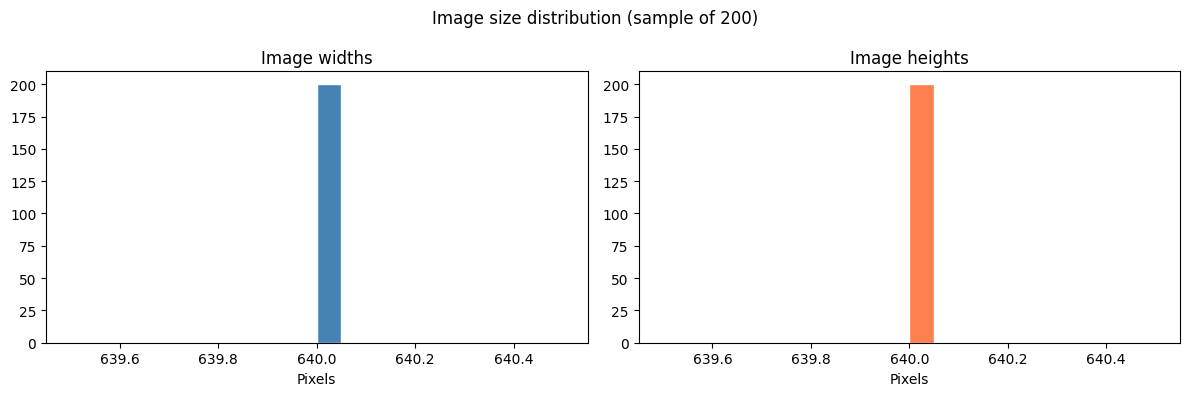

Width:  min=640, max=640, median=640
Height: min=640, max=640, median=640


In [ ]:
checks.check_image_sizes(data_dir / 'train')

In [ ]:
checks.check_tensor_stats(train_loader)

After normalisation (should be near mean≈0, std≈1 per channel):
  R: mean=0.157, std=1.123
  G: mean=0.244, std=1.160
  B: mean=0.187, std=1.240


In [ ]:
checks.check_split(train_dataset, val_dataset, train_dataset.classes)

Class                   Train      Val    Val %
----------------------------------------------
akhalTeke                 222       24     9.8%
appaloosa                 189       21    10.0%
arabian                   219       25    10.2%
friesian                  216       24    10.0%
orlovTrotter              225       21     8.5%
percheron                 102       11     9.7%
vladimirHeavyDraft         66        8    10.8%
----------------------------------------------
TOTAL                    1239      134     9.8%


In [ ]:
corrupt = checks.find_corrupt_images(data_dir)

Scanned 1496 images — no corrupt files found.


In [ ]:
# In this example dataset the duplicates are intentionally identical images with the same filename.
# In real datasets duplicates may be similar but not identical, so a high threshold is used.
if RUN_SLOW_CHECKS:
    possible_duplicates = checks.find_train_val_duplicates(train_dataset, val_dataset, device=device)

## 4. Model

Define the model in `src/dlproject/models.py`, then import and build it here.

In [ ]:
import torch

from dlproject.models import build_model

num_classes = len(train_dataset.classes)
model = build_model(num_classes).to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Classes: {num_classes}')
print(f'Trainable: {trainable:,} / {total:,}')
print(model(torch.randn(1, 3, 224, 224).to(device)).shape)

Classes: 7
Trainable: 3,591 / 11,180,103
torch.Size([1, 7])


## 5. Training

Put the training loop in `src/dlproject/train.py`.
Checkpoints are saved to Google Drive in Colab so they survive a runtime restart.

In [ ]:
import torch

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = Path('/content/drive/MyDrive/deepLearning/checkpoints')
else:
    CHECKPOINT_DIR = repo / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = CHECKPOINT_DIR / 'model.pt'

val_loader = get_loader(val_dataset, shuffle=False)

# if TRAIN_MODEL:
#     from dlproject.train import train
#     history = train(model, train_loader, val_loader, device=device, epochs=10)
#     torch.save(model.state_dict(), checkpoint_path)
# else:
#     model.load_state_dict(torch.load(checkpoint_path, map_location=device))

## 6. Evaluation

Accuracy, confusion matrix, example predictions, ...

In [ ]:
# from dlproject.evaluate import evaluate
# evaluate(model, val_loader, class_names=train_dataset.classes, device=device)